# 03b. Оценка параметров сигнала: классическая ЦОС против многозадачной нейросети

**Цель этапа:** кроме вида модуляции, оценивать основные параметры сигнала — ОСШ, сдвиг частоты, символьную
скорость, ширину полосы, roll-off, разнос частот ЧМн — и сравнить нейросеть с классическими методами ЦОС
(baseline второй задачи).

**Данные:** свой датасет `synth/v1` (1024 отсчёта) — только в нём известны все параметры (метаданные генератора).

**Методы:**
- классические оценщики `src/amc/estimators.py` (спектральная «полка» и M2M4 для ОСШ, линия z^M и центр тяжести
  спектра для сдвига частоты, линия спектра огибающей / |Δf| для скорости, полоса 99 % по спектру Уэлча и т.д.);
  там, где метод зависит от вида модуляции, ему дан **истинный класс** (оракул) — это верхняя граница для
  каскада «классификатор → оценщик»;
- многозадачная сеть `src/amc/multitask.py`: общий ResNet-1D-энкодер, голова классификации и голова регрессии
  6 параметров, маскированная функция потерь Хьюбера (параметр учитывается только у тех классов, где он определён).

**Шаги:** 1) качество классификации многозадачной сети; 2) ошибки параметров по ОСШ — ЦОС против сети;
3) значимость различий (Уилкоксон для парных ошибок); 4) гибрид; 5) выводы.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon

from amc import estimators as est
from amc.data import load_synth
from amc.multitask import TARGETS, make_targets

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "parameters"
FIG.mkdir(parents=True, exist_ok=True)
DEEP = ROOT / "models" / "deep"
sns.set_theme(style="whitegrid")
NAMES = {"snr_db": "ОСШ, дБ", "cfo": "сдвиг частоты, % fs", "log2_rate": "log2 символьной скорости",
         "log2_bw": "log2 полосы 99 %", "rolloff": "roll-off", "log2_shift": "log2 разноса ЧМн"}


def savefig(name: str) -> None:
    """Сохранить рисунок."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


X, meta, CLASSES = load_synth("v1")
te = np.flatnonzero(meta["split"].to_numpy() == "test")
T = make_targets(meta)[te]
snr = meta["snr_db"].to_numpy()[te]
y = meta["label"].to_numpy()[te]
runs = sorted(p.parent.name for p in DEEP.glob("synth_v1_1024_multitask_s*/pred.npz"))
print("запуски многозадачной сети:", runs)

запуски многозадачной сети: ['synth_v1_1024_multitask_s0', 'synth_v1_1024_multitask_s0_e60', 'synth_v1_1024_multitask_s1', 'synth_v1_1024_multitask_s1_e60', 'synth_v1_1024_multitask_s2', 'synth_v1_1024_multitask_s2_e60']


## 1. Классификация многозадачной сетью (тест)

In [2]:
rows, PRED = [], {}
for r in runs:
    d = np.load(DEEP / r / "pred.npz", allow_pickle=True)
    p, reg = d["proba"][te], d["reg"][te]
    PRED[r] = reg
    c = p.argmax(1) == y
    rows.append({"запуск": r, "acc": c.mean(), "acc ОСШ≥0": c[snr >= 0].mean(), "acc ОСШ≥10": c[snr >= 10].mean()})
pd.DataFrame(rows).set_index("запуск").round(4)

,acc,acc ОСШ≥0,acc ОСШ≥10
запуск,,,
synth_v1_1024_multitask_s0,0.5654,0.8212,0.8525
synth_v1_1024_multitask_s0_e60,0.4997,0.7309,0.7580
synth_v1_1024_multitask_s1,0.5588,0.8114,0.8480
synth_v1_1024_multitask_s1_e60,0.5421,0.7904,0.8262
synth_v1_1024_multitask_s2,0.6048,0.8737,0.9046
synth_v1_1024_multitask_s2_e60,0.5052,0.7456,0.7745


## 2. Классические оценки

In [3]:
z = np.asarray(X[te]).astype(np.float64)
z = z[:, 0] + 1j * z[:, 1]
cls = meta["cls"].to_numpy()[te]
parts = [est.estimate_all(z[i:i + 4000], cls[i:i + 4000]) for i in range(0, len(z), 4000)]
E = {k: np.concatenate([q[k] for q in parts]) for k in parts[0]}
C = np.stack([E["snr_db"], E["cfo"] * 100, np.log2(np.clip(E["symbol_rate"], 1e-6, None)),
              np.log2(np.clip(E["bw99"], 1e-6, None)), E["rolloff"],
              np.log2(np.clip(E["fsk_shift"], 1e-6, None))], axis=1)
C_m2m4 = E["snr_db_m2m4"]
MASK = ~np.isnan(T)

## 3. Ошибки в зависимости от ОСШ
Медиана абсолютной ошибки (устойчива к единичным «срывам» оценщиков) и среднее (чувствительно к срывам).

лучший по val: synth_v1_1024_multitask_s2


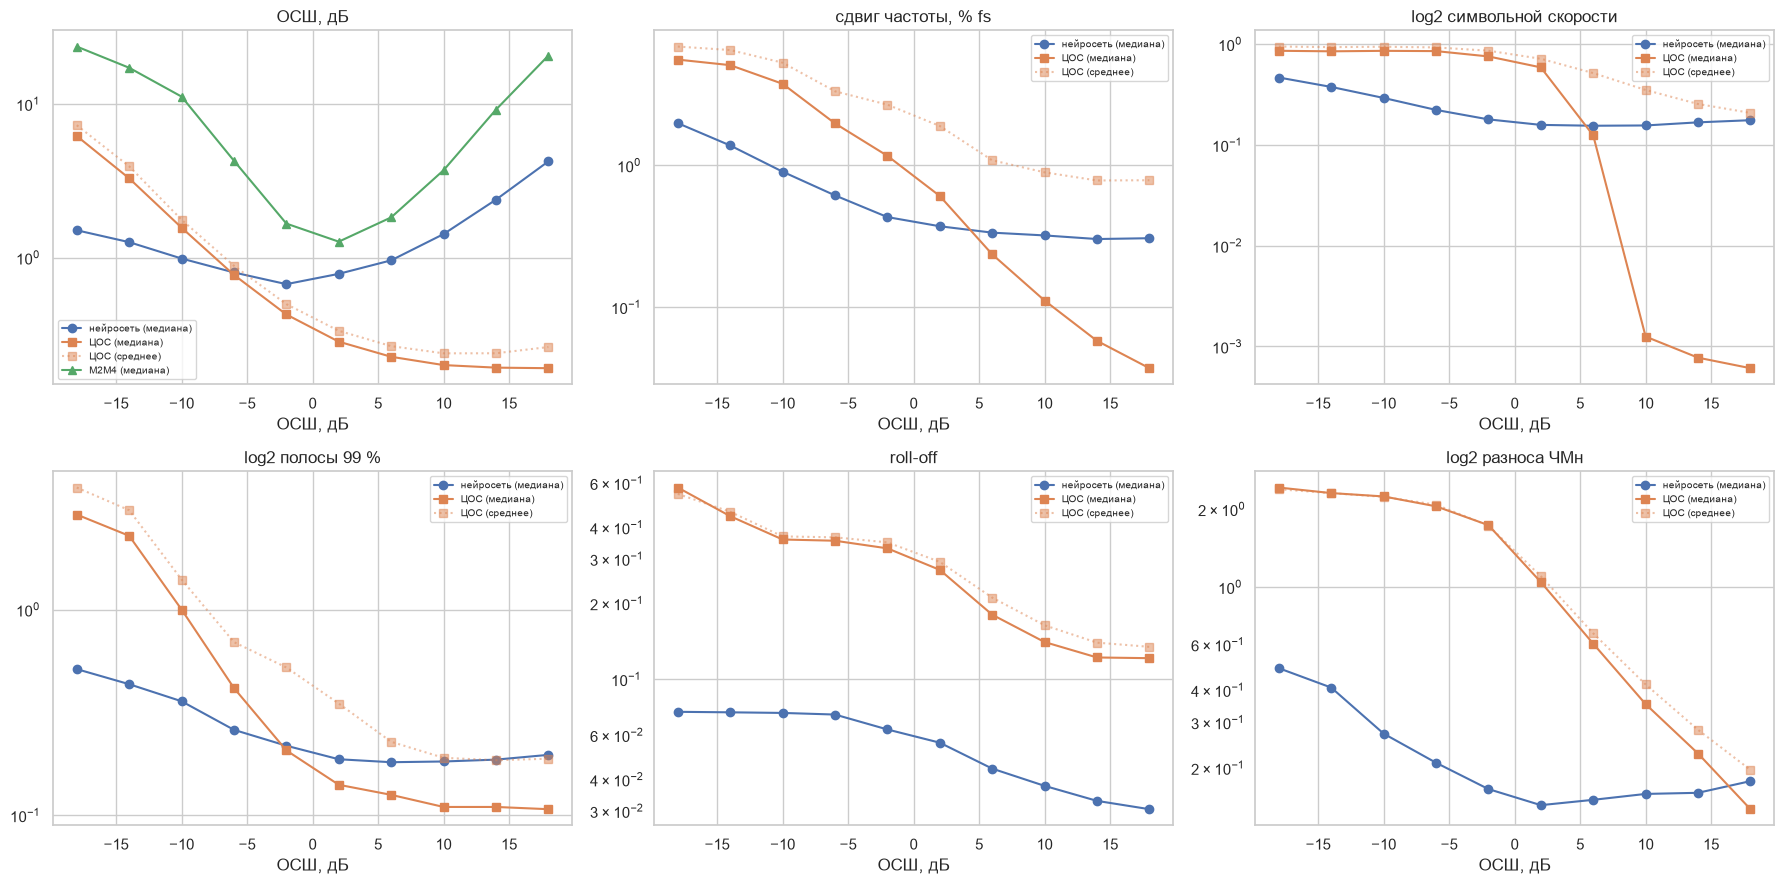

,параметр,ОСШ,медиана ош. сеть,медиана ош. ЦОС,лучше,p Уилкоксон
0,"ОСШ, дБ",-20…0,0.9808,1.4402,сеть,0.0
1,"ОСШ, дБ",0…20,1.6643,0.2135,ЦОС,0.0
2,"сдвиг частоты, % fs",-20…0,0.9007,3.3275,сеть,0.0
3,"сдвиг частоты, % fs",0…20,0.3244,0.1749,ЦОС,0.0
4,log2 символьной скорости,-20…0,0.2838,0.8359,сеть,0.0
5,log2 символьной скорости,0…20,0.1619,0.0019,ЦОС,0.0
6,log2 полосы 99 %,-20…0,0.3330,1.1699,сеть,0.0
7,log2 полосы 99 %,0…20,0.1857,0.1155,ЦОС,0.0
8,roll-off,-20…0,0.0714,0.3961,сеть,0.0
9,roll-off,0…20,0.0395,0.1532,сеть,0.0


In [4]:
# лучший запуск выбирается по val (средняя |ошибка| параметров), тест для выбора не используется
va_idx = np.flatnonzero(meta["split"].to_numpy() == "val")
T_val = make_targets(meta)[va_idx]
best = min(runs, key=lambda r: np.nanmean(np.abs(np.load(DEEP / r / "pred.npz", allow_pickle=True)["reg"][va_idx] - T_val)))
print("лучший по val:", best)
R = PRED[best]
bins = np.arange(-20, 21, 4)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
summary_rows = []
for ax, (i, t) in zip(axes.ravel(), enumerate(TARGETS)):
    m = MASK[:, i]
    b = np.digitize(snr[m], bins)
    err_ml = np.abs(R[m, i] - T[m, i])
    err_dsp = np.abs(C[m, i] - T[m, i])
    ctr = bins[:-1] + 2
    ax.plot(ctr, [np.median(err_ml[b == k]) for k in range(1, len(bins))], "o-", label="нейросеть (медиана)")
    ax.plot(ctr, [np.median(err_dsp[b == k]) for k in range(1, len(bins))], "s-", label="ЦОС (медиана)")
    ax.plot(ctr, [np.mean(err_dsp[b == k]) for k in range(1, len(bins))], "s:", c="C1", alpha=0.5,
            label="ЦОС (среднее)")
    if t == "snr_db":
        e2 = np.abs(C_m2m4[m] - T[m, i])
        ax.plot(ctr, [np.median(e2[b == k]) for k in range(1, len(bins))], "^-", label="M2M4 (медиана)")
    ax.set_yscale("log")
    ax.set_title(NAMES[t])
    ax.set_xlabel("ОСШ, дБ")
    ax.legend(fontsize=7)
    for lo, hi in [(-20, 0), (0, 20)]:
        mm = (snr[m] >= lo) & (snr[m] < hi)
        w = wilcoxon(err_ml[mm], err_dsp[mm])
        summary_rows.append({"параметр": NAMES[t], "ОСШ": f"{lo}…{hi}",
                             "медиана ош. сеть": np.median(err_ml[mm]), "медиана ош. ЦОС": np.median(err_dsp[mm]),
                             "лучше": "сеть" if np.median(err_ml[mm] - err_dsp[mm]) < 0 else "ЦОС",
                             "p Уилкоксон": w.pvalue})
plt.tight_layout()
savefig("errors_vs_snr")
plt.show()
S = pd.DataFrame(summary_rows)
S.round(4)

**Критерий Уилкоксона** (знаковых рангов) для парных ошибок: на одних и тех же примерах сравниваются
|ошибка сети| и |ошибка ЦОС|; непараметрический, т.к. распределения ошибок сильно скошены (срывы оценщиков).

## 4. Гибрид
Для каждого параметра и интервала ОСШ берётся метод, который лучше на **val** (не на тесте), затем гибрид
проверяется на тесте. ОСШ интервала для выбора берётся по оценке самой сети (истинный ОСШ в реальной
работе неизвестен).

In [5]:
va = np.flatnonzero(meta["split"].to_numpy() == "val")
Tv = make_targets(meta)[va]
zv = np.asarray(X[va]).astype(np.float64)
zv = zv[:, 0] + 1j * zv[:, 1]
pv = [est.estimate_all(zv[i:i + 4000], meta["cls"].to_numpy()[va][i:i + 4000]) for i in range(0, len(zv), 4000)]
Ev = {k: np.concatenate([q[k] for q in pv]) for k in pv[0]}
Cv = np.stack([Ev["snr_db"], Ev["cfo"] * 100, np.log2(np.clip(Ev["symbol_rate"], 1e-6, None)),
               np.log2(np.clip(Ev["bw99"], 1e-6, None)), Ev["rolloff"],
               np.log2(np.clip(Ev["fsk_shift"], 1e-6, None))], axis=1)
Rv = np.load(DEEP / best / "pred.npz", allow_pickle=True)["reg"][va]
edges = [-np.inf, -10, 0, 10, np.inf]
choice = {}
for i, t in enumerate(TARGETS):
    for k in range(4):
        m = ~np.isnan(Tv[:, i]) & (Rv[:, 0] >= edges[k]) & (Rv[:, 0] < edges[k + 1])
        choice[(t, k)] = "ЦОС" if np.median(np.abs(Cv[m, i] - Tv[m, i])) < np.median(np.abs(Rv[m, i] - Tv[m, i])) else "сеть"
H = R.copy()
kbin = np.digitize(R[:, 0], edges[1:-1])
for i, t in enumerate(TARGETS):
    for k in range(4):
        if choice[(t, k)] == "ЦОС":
            H[kbin == k, i] = C[kbin == k, i]
rows = []
for i, t in enumerate(TARGETS):
    m = MASK[:, i]
    rows.append({"параметр": NAMES[t], "сеть": np.median(np.abs(R[m, i] - T[m, i])),
                 "ЦОС": np.median(np.abs(C[m, i] - T[m, i])), "гибрид": np.median(np.abs(H[m, i] - T[m, i])),
                 "выбор по интервалам ОСШ (<−10, −10…0, 0…10, >10)": " / ".join(choice[(t, k)] for k in range(4))})
pd.DataFrame(rows).set_index("параметр").round(4)

,сеть,ЦОС,гибрид,"выбор по интервалам ОСШ (<−10, −10…0, 0…10, >10)"
параметр,,,,
"ОСШ, дБ",1.2752,0.4224,0.3881,сеть / ЦОС / ЦОС / ЦОС
"сдвиг частоты, % fs",0.4999,1.1667,0.5663,сеть / сеть / ЦОС / ЦОС
log2 символьной скорости,0.2081,0.4992,0.1860,сеть / сеть / сеть / ЦОС
log2 полосы 99 %,0.2411,0.2563,0.1926,сеть / сеть / ЦОС / ЦОС
roll-off,0.0536,0.2661,0.0536,сеть / сеть / сеть / сеть
log2 разноса ЧМн,0.2038,1.1940,0.2038,сеть / сеть / сеть / сеть


## 5. Выводы

1. **Многозадачная сеть** (общий энкодер ResNet-1D + голова регрессии 6 параметров) классифицирует почти как
   одиночная ResNet: лучший по val запуск (s2, 25 эпох) — 60,5 % (ОСШ ≥ 0: 87,4 %). Запуски на 60 эпох
   хуже (50–54 %) — тот же эффект переобучения/раннего останова, что и в 03.
2. **Ни один подход не лучше везде** (Уилкоксон для парных ошибок, все p < 1e-300 — различия значимы):
   - при ОСШ > 0 дБ **ЦОС точнее** для ОСШ (медиана ошибки 0,21 дБ против 1,66 у сети), сдвига частоты
     (0,17 % fs против 0,32), символьной скорости (log2-ошибка 0,002 ≈ 0,13 % против 0,16 ≈ 12 %) и полосы;
   - при ОСШ < 0 дБ **сеть точнее по всем параметрам**: классические оценщики «срываются» (ошибка скорости ×1,8,
     сдвига частоты 3,3 % fs);
   - **roll-off и разнос ЧМн сеть оценивает лучше при любом ОСШ** (roll-off 0,04 против 0,15 при ОСШ > 0):
     классические методы для них чувствительны к многолучёвости, которая искажает форму спектра.
3. **Гибрид** (метод выбирается на val для каждого параметра и интервала ОСШ, ОСШ — по оценке самой сети) —
   лучший или равный лучшему по всем параметрам на тесте: ОСШ 0,39 дБ (сеть 1,28, ЦОС 0,42), скорость
   log2 0,19 (0,21 / 0,50), полоса 0,19 (0,24 / 0,26); сдвиг частоты — 0,57 против 0,50 у сети (единственный
   случай, где выбор на val чуть хуже лучшего на тесте). Выбранные границы перенесены в продукт (`infer.py`).
4. M2M4 (классический оценщик ОСШ по моментам) на сигналах с RRC-фильтром требует калибровки ka и при высоком ОСШ
   неустойчив (см. tools/m2m4_check.py), поэтому основным ЦОС-оценщиком ОСШ выбран спектральный.
5. Практический вывод: **ML не заменяет ЦОС, а дополняет её** — сеть надёжна в шуме и для параметров формы
   спектра, классические методы дают на порядок более точные оценки там, где сигнал хорошо виден.